# Examen Partial PMP


## Subiectul 1. Model Markov ascuns

In [1]:
import numpy as np

# Definirea starilor si a observatiilor
states = [1, 2, 3, 4]
obs_map = {'red': 0, 'green': 1, 'blue': 2}
obs_seq_str = ['red', 'green', 'blue', 'blue', 'red']
obs_seq = [obs_map[o] for o in obs_seq_str]
# Distributia initiala (uniforma)
pi = np.array([0.25, 0.25, 0.25, 0.25])

# Matricea de emisii B (randuri: camere 1..4, coloane: red, green, blue)
B = np.array([
    [0.7, 0.2, 0.1],  # Camera 1
    [0.2, 0.6, 0.2],  # Camera 2
    [0.1, 0.3, 0.6],  # Camera 3
    [0.5, 0.2, 0.3]   # Camera 4
])

# Matricea de tranzitie pentru punctul (a)
A_a = np.array([
    [0.2, 0.4, 0.0, 0.4],  # din 1
    [0.4, 0.2, 0.4, 0.0],  # din 2
    [0.0, 0.4, 0.2, 0.4],  # din 3
    [0.4, 0.0, 0.4, 0.2]   # din 4
])

# Matricea de tranzitie pentru punctul (b) - fara stationare
A_b = np.array([
    [0.0, 0.5, 0.0, 0.5],  # din 1
    [0.5, 0.0, 0.5, 0.0],  # din 2
    [0.0, 0.5, 0.0, 0.5],  # din 3
    [0.5, 0.0, 0.5, 0.0]   # din 4
])


def viterbi(obs, pi, A, B, states):
    T = len(obs)
    N = len(states)
    
    # dp[t, j] = probabilitatea maxima a unei secvente de stari pana la pasul t care se termina in starea j
    dp = np.zeros((T, N))
    backptr = np.zeros((T, N), dtype=int)
    
    # Initializare (t = 0)
    dp[0] = pi * B[:, obs[0]]
    
    # Recurenta (t = 1 .. T-1)
    for t in range(1, T):
        for j in range(N):
            probs = dp[t - 1] * A[:, j] * B[j, obs[t]]
            backptr[t, j] = np.argmax(probs)
            dp[t, j] = probs[backptr[t, j]]
            
    # Reconstruirea celei mai probabile secvente
    best_last = np.argmax(dp[T - 1])
    best_prob = dp[T - 1, best_last]
    
    path_idx = [0] * T
    path_idx[T - 1] = best_last
    for t in range(T - 2, -1, -1):
        path_idx[t] = backptr[t + 1, path_idx[t + 1]]
        
    best_path = [states[i] for i in path_idx]
    return best_path, best_prob, dp


# Rezolvare (a)
path_a, prob_a, dp_a = viterbi(obs_seq, pi, A_a, B, states)
print("Subiectul 1 (a)")
print(f"Cea mai probabila secventa de camere: {path_a}")
print(f"Probabilitatea comuna P(Q*, O): {prob_a:.9f} (log P = {np.log(prob_a):.6f})")

# Rezolvare (b)
path_b, prob_b, dp_b = viterbi(obs_seq, pi, A_b, B, states)
print("Subiectul 1 (b)")
print(f"Cea mai probabila secventa de camere: {path_b}")
print(f"Probabilitatea comuna P(Q*, O): {prob_b:.9f} (log P = {np.log(prob_b):.6f})")
print(f"Raportul probabilitatilor prob_b / prob_a: {prob_b / prob_a:.6f} (exact (0.5/0.4)^4 = {(0.5/0.4)**4:.6f})")


Subiectul 1 (a)
Cea mai probabila secventa de camere: [1, 2, 3, 4, 1]
Probabilitatea comuna P(Q*, O): 0.000338688 (log P = -7.990431)
Subiectul 1 (b)
Cea mai probabila secventa de camere: [1, 2, 3, 4, 1]
Probabilitatea comuna P(Q*, O): 0.000826875 (log P = -7.097857)
Raportul probabilitatilor prob_b / prob_a: 2.441406 (exact (0.5/0.4)^4 = 2.441406)


Comparatie rezultate 1(a) vs 1(b)
1. Secventa optima de camere este identica in ambele cazuri: `[1, 2, 3, 4, 1]`.
   - Chiar si atunci cand robotul avea voie sa ramana pe loc (cazul a), secventa optima nu a inclus nicio stationare. De exemplu, la observatiile consecutive `blue, blue`, ramanerea in camera 3 ar fi avut o probabilitate de tranzitie mai mica (`0.2`) si nu ar fi permis ajungerea directa in camera 1 (care are probabilitate mare pentru ultimul `red`, `0.7`), pe cand trecerea `3 -> 4 -> 1` combina o probabilitate decenta pentru `blue` in camera 4 (`0.3`) cu probabilitatea mare de `red` in camera 1 (`0.7`).
2. Probabilitatea comuna P(Q^*, O) creste semnificativ in cazul (b): de la `0.000338688` la `0.000826875`.
   - Deoarece secventa `[1, 2, 3, 4, 1]` presupune 4 deplasari intre camere vecine si nicio stationare, eliminarea probabilitatii de a ramane pe loc ridica probabilitatea fiecarei tranzitii din secventa optima de la `0.4` la `0.5`. Astfel, probabilitatea comuna se inmulteste exact cu $(0.5 / 0.4)^4 = 1.25^4 = 2.44140625$.



## Subiectul 2. Retele Markov

### (a) $P(A, B, C, D, E) = \frac{1}{Z} \phi_1(A, B) \phi_2(B, C) \phi_3(C, D) \phi_4(D, E)$

**Reteaua Markov asociata:**
Fiecare potential defineste o clica in graful neorientat. Potentialele de perechi $(A,B)$, $(B,C)$, $(C,D)$, $(D,E)$ formeaza un **lant**:
`A --- B --- C --- D --- E`

**Calculul lui $P(A \mid B, C)$:**
Marginalizam variabilele $D$ si $E$ pentru a obtine $P(A, B, C)$:
$$P(A, B, C) = \sum_{D, E} P(A, B, C, D, E) = \frac{1}{Z} \phi_1(A, B) \phi_2(B, C) \sum_{D, E} \phi_3(C, D) \phi_4(D, E)$$

$$P(B, C) = \sum_{A'} P(A', B, C) = \frac{1}{Z} \phi_2(B, C) \left( \sum_{D, E} \phi_3(C, D) \phi_4(D, E) \right) \sum_{A'} \phi_1(A', B)$$

Facand raportul $P(A \mid B, C) = \frac{P(A, B, C)}{P(B, C)}$, factorii care nu depind de $A$ ($\frac{1}{Z}$, $\phi_2(B, C)$ si suma dupa $D, E$) se simplifica:
$$P(A \mid B, C) = \frac{\phi_1(A, B)}{\sum_{A'} \phi_1(A', B)} = \frac{1}{Z_{A|B}} \phi_1(A, B)$$
unde constanta de normalizare este $Z_{A|B} = \sum_{A'} \phi_1(A', B)$.

*(In graful lant, $B$ separa pe $A$ de $C$, deci $A \perp C \mid B$, ceea ce confirma ca $P(A \mid B, C) = P(A \mid B)$.)*

---

### (b) $P(A, B, C, D, E) = \frac{1}{Z} \psi_1(A, B, C) \psi_2(B, D) \psi_3(C, E)$

**Reteaua Markov asociata:**
- Potentialul $\psi_1(A, B, C)$ induce o clica completa (un triunghi) intre nodurile $A, B, C$: muchiile $(A,B)$, $(B,C)$ si $(A,C)$.
- Potentialul $\psi_2(B, D)$ induce muchia $(B, D)$.
- Potentialul $\psi_3(C, E)$ induce muchia $(C, E)$.

$$P(D \mid A, B, C, E) = \frac{P(A, B, C, D, E)}{P(A, B, C, E)} = \frac{P(A, B, C, D, E)}{\sum_{D'} P(A, B, C, D', E)}$$

$$P(D \mid A, B, C, E) = \frac{\frac{1}{Z} \psi_1(A, B, C) \psi_2(B, D) \psi_3(C, E)}{\frac{1}{Z} \psi_1(A, B, C) \psi_3(C, E) \sum_{D'} \psi_2(B, D')}$$

Factorii $\frac{1}{Z}$, $\psi_1(A, B, C)$ si $\psi_3(C, E)$ nu depind de $D$ si se simplifica:
$$P(D \mid A, B, C, E) = \frac{\psi_2(B, D)}{\sum_{D'} \psi_2(B, D')} = \frac{1}{Z_{D|B}} \psi_2(B, D)$$
unde constanta de normalizare este $Z_{D|B} = \sum_{D'} \psi_2(B, D')$.


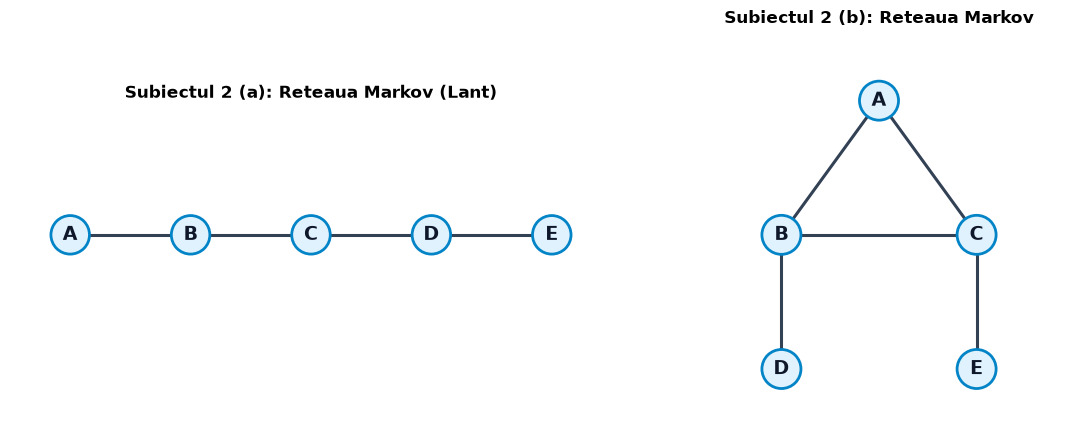

In [2]:
import matplotlib.pyplot as plt

def draw_markov_network(ax, pos, edges, title):
    # Desenare muchii
    for u, v in edges:
        x_vals = [pos[u][0], pos[v][0]]
        y_vals = [pos[u][1], pos[v][1]]
        ax.plot(x_vals, y_vals, color='#334155', linewidth=2.2, zorder=1)
        
    # Desenare noduri
    for node, (x, y) in pos.items():
        circle = plt.Circle((x, y), 0.16, facecolor='#e0f2fe', edgecolor='#0284c7', linewidth=2, zorder=2)
        ax.add_patch(circle)
        ax.text(x, y, node, fontsize=14, fontweight='bold', ha='center', va='center', color='#0f172a', zorder=3)
        
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_aspect('equal')
    ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Graf (a): A - B - C - D - E
pos_a = {'A': (0, 0), 'B': (1, 0), 'C': (2, 0), 'D': (3, 0), 'E': (4, 0)}
edges_a = [('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E')]
draw_markov_network(axes[0], pos_a, edges_a, 'Subiectul 2 (a): Reteaua Markov (Lant)')
axes[0].set_xlim(-0.5, 4.5)
axes[0].set_ylim(-1.0, 1.0)

# Graf (b): Triunghi (A, B, C) + muchii (B, D) si (C, E)
pos_b = {'A': (1.0, 1.4), 'B': (0.2, 0.3), 'C': (1.8, 0.3), 'D': (0.2, -0.8), 'E': (1.8, -0.8)}
edges_b = [('A', 'B'), ('B', 'C'), ('A', 'C'), ('B', 'D'), ('C', 'E')]
draw_markov_network(axes[1], pos_b, edges_b, 'Subiectul 2 (b): Reteaua Markov')
axes[1].set_xlim(-0.5, 2.5)
axes[1].set_ylim(-1.3, 1.9)

plt.tight_layout()
plt.show()


## Subiectul 3. Inferenta Bayesiana


Daca priorul este $\text{Beta}(\alpha, \beta)$ si observam $k$ succese (defecte) din $n$ incercari, distributia *a posteriori* este:
$$\theta \mid k, n \sim \text{Beta}(\alpha + k, \beta + n - k)$$
$E[\theta \mid k, n] = \frac{\alpha + k}{\alpha + \beta + n}$ si $\text{Var}(\theta \mid k, n) = \frac{(\alpha + k)(\beta + n - k)}{(\alpha + \beta + n)^2 (\alpha + \beta + n + 1)}$.

**(a) Dupa primul lot:**
  $$\theta \mid \text{lot}_1 \sim \text{Beta}(2 + 5, 8 + 15) = \text{Beta}(7, 23)$$
  $E[\theta \mid \text{lot}_1] = \frac{7}{7 + 23} = \frac{7}{30} \approx 0.2333$.

**(b) Dupa ambele loturi (actualizare secventiala sau combinata: $k = 5 + 3 = 8$, $n = 20 + 15 = 35$):**
  $$\theta \mid \text{lot}_1, \text{lot}_2 \sim \text{Beta}(7 + 3, 23 + 12) = \text{Beta}(10, 35)$$
  $E[\theta \mid \text{lot}_1, \text{lot}_2] = \frac{10}{10 + 35} = \frac{10}{45} = \frac{2}{9} \approx 0.2222$.

**(c) Folosind numai al doilea lot si priorul initial $\text{Beta}(2, 8)$:**
  $$\theta \mid \text{lot}_2 \sim \text{Beta}(2 + 3, 8 + 12) = \text{Beta}(5, 20)$$
  $E[\theta \mid \text{lot}_2] = \frac{5}{5 + 20} = \frac{5}{25} = 0.2000$.


Rezultate Subiectul 3
Prior initial       : Beta(2, 8) | Media = 0.2000 | Varianta = 0.014545 | Std = 0.1206
(a) Dupa lotul 1    : Beta(7, 23) | Media = 0.2333 | Varianta = 0.005771 | Std = 0.0760
(b) Dupa ambele     : Beta(10, 35) | Media = 0.2222 | Varianta = 0.003757 | Std = 0.0613
(c) Doar lotul 2    : Beta(5, 20) | Media = 0.2000 | Varianta = 0.006154 | Std = 0.0784


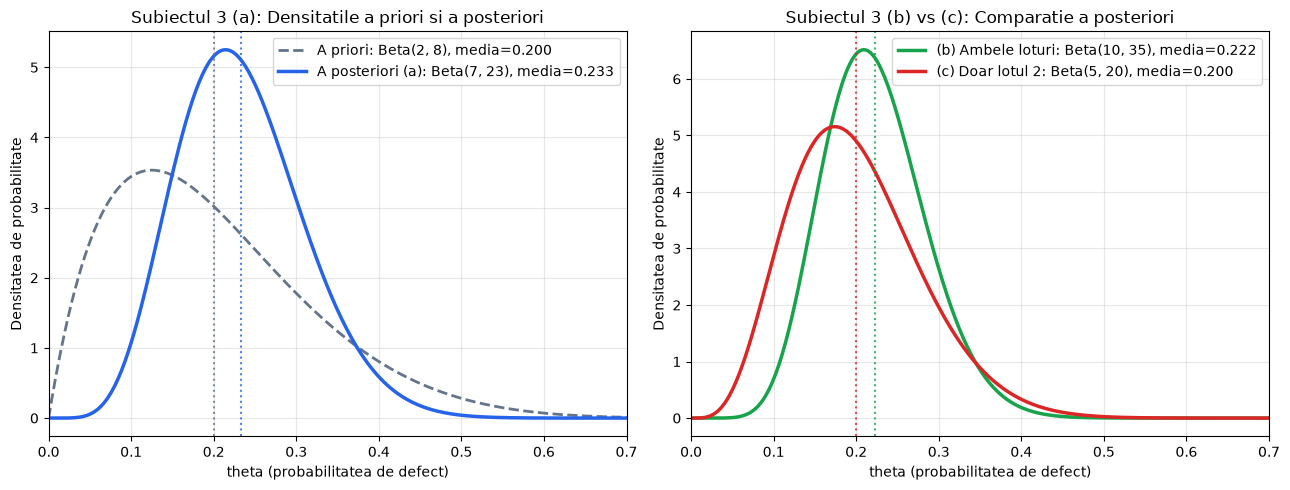

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Parametri prior
a0, b0 = 2, 8

# Lot 1: 5 defecte din 20
n1, k1 = 20, 5
a1, b1 = a0 + k1, b0 + (n1 - k1)

# Lot 2: 3 defecte din 15
n2, k2 = 15, 3
# (b) Dupa ambele loturi
a_b, b_b = a1 + k2, b1 + (n2 - k2)
# (c) Doar lotul 2 + prior initial
a_c, b_c = a0 + k2, b0 + (n2 - k2)

def print_beta_stats(label, a, b):
    mean = a / (a + b)
    var = (a * b) / (((a + b) ** 2) * (a + b + 1))
    std = np.sqrt(var)
    print(f"{label}: Beta({a}, {b}) | Media = {mean:.4f} | Varianta = {var:.6f} | Std = {std:.4f}")

print("Rezultate Subiectul 3")
print_beta_stats("Prior initial       ", a0, b0)
print_beta_stats("(a) Dupa lotul 1    ", a1, b1)
print_beta_stats("(b) Dupa ambele     ", a_b, b_b)
print_beta_stats("(c) Doar lotul 2    ", a_c, b_c)

# Grafice
theta = np.linspace(0, 1, 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafic pentru (a): Prior vs Posterior dupa lotul 1
axes[0].plot(theta, beta.pdf(theta, a0, b0), label=f'A priori: Beta({a0}, {b0}), media={a0/(a0+b0):.3f}', lw=2, linestyle='--', color='#64748b')
axes[0].plot(theta, beta.pdf(theta, a1, b1), label=f'A posteriori (a): Beta({a1}, {b1}), media={a1/(a1+b1):.3f}', lw=2.5, color='#2563eb')
axes[0].axvline(a0/(a0+b0), color='#64748b', linestyle=':', alpha=0.8)
axes[0].axvline(a1/(a1+b1), color='#2563eb', linestyle=':', alpha=0.8)
axes[0].set_title('Subiectul 3 (a): Densitatile a priori si a posteriori')
axes[0].set_xlabel('theta (probabilitatea de defect)')
axes[0].set_ylabel('Densitatea de probabilitate')
axes[0].set_xlim(0, 0.7)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Grafic comparativ pentru (b) vs (c)
axes[1].plot(theta, beta.pdf(theta, a_b, b_b), label=f'(b) Ambele loturi: Beta({a_b}, {b_b}), media={a_b/(a_b+b_b):.3f}', lw=2.5, color='#16a34a')
axes[1].plot(theta, beta.pdf(theta, a_c, b_c), label=f'(c) Doar lotul 2: Beta({a_c}, {b_c}), media={a_c/(a_c+b_c):.3f}', lw=2.5, color='#dc2626')
axes[1].axvline(a_b/(a_b+b_b), color='#16a34a', linestyle=':', alpha=0.8)
axes[1].axvline(a_c/(a_c+b_c), color='#dc2626', linestyle=':', alpha=0.8)
axes[1].set_title('Subiectul 3 (b) vs (c): Comparatie a posteriori')
axes[1].set_xlabel('theta (probabilitatea de defect)')
axes[1].set_ylabel('Densitatea de probabilitate')
axes[1].set_xlim(0, 0.7)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Comparatie si explicatie pentru 3(b) vs 3(c)
1. **Diferenta de medie (deplasarea distributiei):**
   - La **(b)** distributia este $\text{Beta}(10, 35)$ cu media $10/45 \approx 0.2222$, mai mare decat la **(c)**, unde distributia este $\text{Beta}(5, 20)$ cu media $5/25 = 0.2000$.
   - Explicatia este ca in primul lot rata empirica a defectelor a fost $5/20 = 0.25$, mai mare decat media a priori ($0.20$) si decat rata din al doilea lot ($3/15 = 0.20$). Includerea primului lot in **(b)** trage estimarea lui $\theta$ in sus. In **(c)**, deoarece rata observata in lotul 2 ($0.20$) coincide exact cu media a priori ($0.20$), media ramane neschimbata la $0.20$.
2. **Diferenta de varianta / incertitudine (latimea distributiei):**
   - Distributia de la **(b)** este mai ascutita si mai concentrata in jurul mediei (varianta $\approx 0.003757$, deviatie standard $\approx 0.0613$), comparativ cu cea de la **(c)** (varianta $\approx 0.006154$, deviatie standard $\approx 0.0784$).
   - Motivul este volumul total de informatii acumulate: la **(b)** estimarea se bazeaza pe $35$ de produse observate ($\alpha + \beta = 45$), in timp ce la **(c)** se bazeaza pe doar $15$ produse ($\alpha + \beta = 25$). Mai multe date reduc incertitudinea asupra parametrului necunoscut $\theta$.
